In [138]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import solve_ivp
from numba import jit

# Synchronous

In [139]:
def simulate_synch(n,p):
    A=np.zeros([2**n,n+1])
    A[0,0]=1
    if np.random.uniform(0,1)<p:
        A[0,1]=1
        A[1,1]=1
    else:
        pos=np.random.binomial(1,0.5)
        A[pos,1]=1
    for j in range(n):
        for i in range(2**j):
            if A[i,j]==1:
                if np.random.uniform(0,1)<p:
                    A[2*i,j+1]=1
                    A[2*i+1,j+1]=1
                else:
                    pos=np.random.binomial(1,0.5)
                    A[2*i+pos,j+1]=1    
    return A
def find_parent(i,j):
    if i%2==0:
        i_st=int(i/2)
    else:
        i_st=int((i-1)/2)
    return [i_st,j-1]

In [140]:
n=10   #number of generations
p = 0.5 #probability of replication
A=simulate_synch(n,p)       

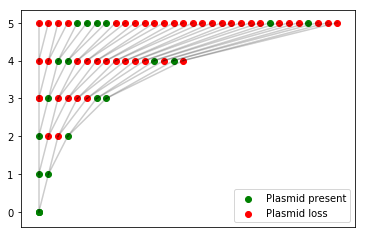

After 10 generations, the fraction of plasmid-free cells is 0.9434


In [141]:
plt.scatter([0],[0],color='g')
count_p=count_l=0
maxx=5
for j in range(maxx+1):
    for i in range(2**j):
        if A[i,j]==1:
            color='g'
        else:
            color='r'
        plt.scatter([i],[j],color=color)
        if not([i,j]==[0,0]):
            [i_st,j_st]=find_parent(i,j)
            plt.plot([i_st,i],[j_st,j],alpha=0.2,color='k')
plt.yticks(range(n+1))
plt.xticks([])
### for legend
plt.scatter([0],[0],color='g',label='Plasmid present')
leg=np.where(A==0)
plt.scatter([leg[0][0]],[leg[1][0]],color='r',label='Plasmid loss')
plt.legend()
plt.show()
print('After %d generations, the fraction of plasmid-free cells is %0.4f' %(n,np.sum(A[:,-1]==0)/2**n))

In [148]:
#multiple simulations
n_vec=[8,9,10,11,12,13]   #number of generations
p = 0.5 #probability of replication
repeats=1000
prob_vec=np.zeros(len(n_vec))
for k in range(len(n_vec)):
    prob=0
    for i in range(repeats):
        A_st=simulate_synch(n_vec[k],p)
        prob+=np.sum(A_st[:,-1]==0)/2**n_vec[k]
    prob_vec[k]=prob/repeats
#print('With %d repeated experiments of %d synchronuous cell divisions, the fraction of plasmid-free cells is %0.4f' %(repeats,n,prob/repeats))

Text(0, 0.5, 'Probability of plasmid loss')

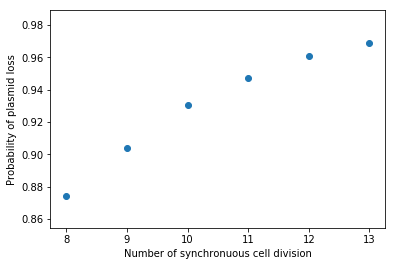

In [149]:
plt.scatter(n_vec,prob_vec)
plt.xlabel('Number of synchronuous cell division')
plt.ylabel('Probability of plasmid loss')

In [150]:
prob_vec

array([0.87435156, 0.9035625 , 0.930625  , 0.94738672, 0.960771  ,
       0.96917957])

# Asynchronous

In [151]:
def simulate(p,T,div_time):
    N=10000
    F=np.zeros(N)  #final plasmid copy number
    ti=np.zeros(N)  #initial time
    tf=np.zeros(N)  #time of division
    par=np.zeros(N) #cell parent 
    t_list = np.ones(N)*2 #list of completed lineages
    ti[0]=0
    F[0]=1
    tf[0]=div_time
    check = 1
    current=0
    last=0
    while check >0:
        t_list[current]=1
        #print(current)
        if F[current]==1:
            if np.random.uniform(0,1)<p:
                for j in np.arange(1,3):
                    F[last+j]=1
                    tf[last+j]=tf[current]+div_time  
            else:
                pos=np.random.binomial(1,0.5)+1
                for j in np.arange(1,3):
                    if pos==j:
                        F[last+j]=1
                        tf[last+j]=tf[current]+div_time
                    else:
                        F[last+j]=0
                        tf[last+j]=tf[current]+1
        else:
            for j in np.arange(1,3):
                tf[last+j]=tf[current]+1
                
        for j in np.arange(1,3):
            if tf[last+j]>=T:
                t_list[last+j]=1
            else:
                t_list[last+j]=0
            ti[last+j]=tf[current]
            par[last+j]=current  
        last+=2
        if sum(t_list==0)==0:
            check=0
        else:
            current=int(np.min(np.where(t_list==0)))
            check=np.sum(t_list==0)
            #print(current,tf[current],check)
    return F,ti,tf,par

In [163]:
p=0.5
T=4
div_time=0.5
F,ti,tf,par= simulate(p,T,div_time)

C:\ProgramData\Anaconda3\lib\site-packages\networkx\drawing\nx_pylab.py:611: MatplotlibDeprecationWarning: isinstance(..., numbers.Number)
  if cb.is_numlike(alpha):


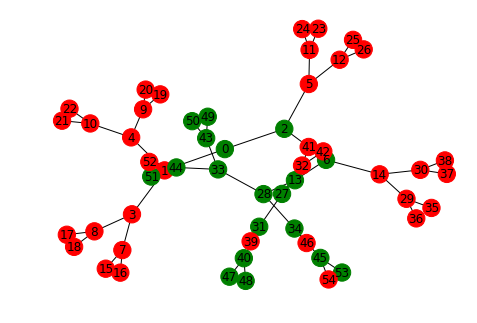

In [345]:
import networkx as nx
maxx = np.max(np.where(tf>0))
connect = np.zeros([maxx+1,maxx+1])
for i in range(maxx+1):
    if not(par[i]==i):
        connect[int(par[i]),i]=1
G = nx.from_numpy_matrix(connect)  
color_map=[]
for node in G:
    if F[node]==1:
        color_map.append('green')
    else:
        color_map.append('red')
nx.draw(G,with_labels=True,node_color=color_map,size=0.4)
plt.show() 

C:\ProgramData\Anaconda3\lib\site-packages\networkx\drawing\nx_pylab.py:611: MatplotlibDeprecationWarning: isinstance(..., numbers.Number)
  if cb.is_numlike(alpha):


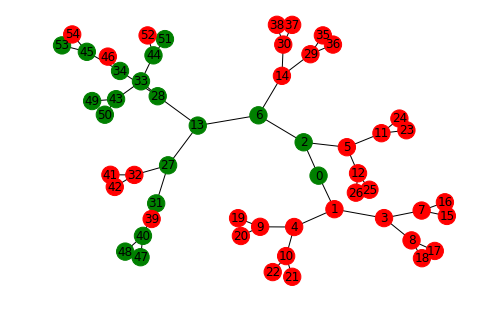

In [357]:
#view intermediate states

import networkx as nx
maxx = np.max(np.where(tf>0))
connect = np.zeros([maxx+1,maxx+1])
for i in range(maxx+1):
    if not(par[i]==i):
        connect[int(par[i]),i]=1
G = nx.from_numpy_matrix(connect)  
color_map=[]
for node in G:
    if F[node]==1:
        color_map.append('green')
    else:
        color_map.append('red')
pos = nx.spring_layout(G)
nx.draw(G,pos,with_labels=True,node_color=color_map,size=0.4)
plt.show() 

C:\ProgramData\Anaconda3\lib\site-packages\networkx\drawing\nx_pylab.py:611: MatplotlibDeprecationWarning: isinstance(..., numbers.Number)
  if cb.is_numlike(alpha):


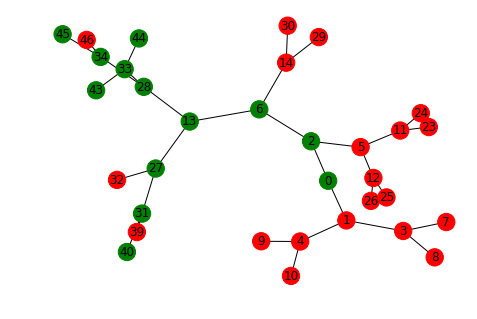

In [358]:
rem=np.where(ti>3)
G.remove_nodes_from(rem[0])
c_map=np.delete(color_map,rem[0])
nx.draw(G,pos,with_labels=True,node_color=c_map,size=0.4)  #

In [245]:
np.ndarray.flatten(rem[0])

array([15, 16, 17, 18, 19, 20, 21, 22, 35, 36, 37, 38, 41, 42, 47, 48, 49,
       50, 51, 52, 53, 54], dtype=int64)

In [224]:
labels

{0: 0,
 1: '1',
 2: '2',
 3: '3',
 4: '4',
 5: '5',
 6: '6',
 7: '7',
 8: '8',
 9: '9',
 10: '10',
 11: '11',
 12: '12',
 13: '13',
 14: '14',
 16: '16',
 17: '17',
 18: '18',
 19: '19',
 20: '20',
 21: '21',
 22: '22',
 23: '23',
 24: '24',
 25: '25',
 26: '26',
 27: '27',
 28: '28',
 29: '29',
 30: '30',
 31: '31',
 32: '32',
 33: '33',
 34: '34',
 35: '35',
 36: '36',
 37: '37',
 38: '38',
 39: '39',
 40: '40',
 41: '41',
 42: '42',
 43: '43',
 44: '44',
 45: '45',
 46: '46',
 47: '47',
 48: '48',
 49: '49',
 50: '50',
 51: '51',
 52: '52',
 53: '53',
 54: '54'}

In [230]:
len(labels)

54

In [228]:
np.shape(con_c)

(33, 33)

In [227]:
labels

{0: 0,
 1: '1',
 2: '2',
 3: '3',
 4: '4',
 5: '5',
 6: '6',
 7: '7',
 8: '8',
 9: '9',
 10: '10',
 11: '11',
 12: '12',
 13: '13',
 14: '14',
 16: '16',
 17: '17',
 18: '18',
 19: '19',
 20: '20',
 21: '21',
 22: '22',
 23: '23',
 24: '24',
 25: '25',
 26: '26',
 27: '27',
 28: '28',
 29: '29',
 30: '30',
 31: '31',
 32: '32',
 33: '33',
 34: '34',
 35: '35',
 36: '36',
 37: '37',
 38: '38',
 39: '39',
 40: '40',
 41: '41',
 42: '42',
 43: '43',
 44: '44',
 45: '45',
 46: '46',
 47: '47',
 48: '48',
 49: '49',
 50: '50',
 51: '51',
 52: '52',
 53: '53',
 54: '54'}

In [105]:
tf[:15]

array([0.5, 1. , 1.5, 1.5, 2. , 2.5, 2.5, 2. , 2.5, 3. , 3. , 2.5, 3. ,
       3. , 0. ])

In [100]:
np.where(tf>0)

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13],
       dtype=int64),)

In [106]:
np.shape(connect)

(14, 14)